# Working with behavioral data

Every model in this series starts from a table of trials. Before fitting anything we need to
load that table, check what each column means, aggregate it without mixing up participants and
trials, and plot it. This notebook does that for a real experiment and introduces the handful of
NumPy, pandas, and Matplotlib idioms used throughout the rest of the series.

**The experiment.** In a *temporal bisection* task, a participant hears or sees a stimulus of a
given duration and decides whether it was closer to a "short" or a "long" reference. The data
come from Zhu, Baykan, Müller & Shi (*Temporal bisection is influenced by ensemble statistics of
the stimulus set*), openly available at
[msenselab/sets_in_bisection](https://github.com/msenselab/sets_in_bisection). In Experiment 1
the same range, 0.4-1.6 s, was sampled with two different spacings: one set crowded at the short
end, the other crowded at the long end. If judgments depended only on the two extremes, the
spacing would not matter.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})

URL = ("https://raw.githubusercontent.com/msenselab/sets_in_bisection/"
       "master/data/AllData_exp1.csv")
raw = pd.read_csv(URL)
raw.shape

(11760, 10)

## A first look

`head()` shows the first rows; `dtypes` shows how pandas parsed each column. Two of the columns
are leftover row numbers from R (`Unnamed: 0` and `X`), which we drop.

In [2]:
raw = raw.drop(columns=["Unnamed: 0", "X"])
print(raw.head())
print()
print(raw.dtypes)

   durNo  cond  curDur  RP  NSub  NT  valid  NB
0     17     1   0.636   0     1   1      0   0
1     12     1   1.008   1     1   2      0   0
2      9     1   0.504   0     1   3      0   0
3      7     1   1.600   1     1   4      0   0
4     18     1   0.800   0     1   5      0   0

durNo       int64
cond        int64
curDur    float64
RP          int64
NSub        int64
NT          int64
valid       int64
NB          int64
dtype: object


The columns we need:

| column | meaning |
|---|---|
| `NSub` | participant |
| `cond` | stimulus spacing (1 or 2) |
| `curDur` | duration on this trial, in seconds |
| `RP` | response: 1 = "long", 0 = "short" |
| `NB` | block number (0 = practice) |
| `valid` | 1 if the trial is kept for analysis |

It is worth confirming a codebook against the data rather than trusting it. Each spacing should
use seven durations between 0.4 and 1.6 s, and practice trials should be the invalid ones.

In [3]:
print(raw.groupby("cond")["curDur"].unique())
print()
print(pd.crosstab(raw["NB"], raw["valid"]))

cond
1    [0.636, 1.008, 0.504, 1.6, 0.8, 1.27, 0.4]
2    [1.496, 0.4, 0.73, 1.2, 1.366, 0.992, 1.6]
Name: curDur, dtype: object

valid     0     1
NB               
0      1680     0
1         0  1680
2         0  1680
3         0  1680
4         0  1680
5         0  1680
6         0  1680


Condition 1 places more durations at the short end (geometric spacing); condition 2 places more
at the long end. All invalid trials are in block 0, the practice block. We keep the valid
trials and give the conditions readable names.

In [4]:
df = (raw.query("valid == 1")
         .assign(spacing=lambda d: d["cond"].map({1: "dense-short", 2: "dense-long"}))
         .rename(columns={"NSub": "subject", "curDur": "duration", "RP": "long"})
         [["subject", "spacing", "duration", "long", "NB"]])
print(df.head())
print(f"{df['subject'].nunique()} participants, {len(df)} trials, "
      f"{len(df) // df['subject'].nunique()} per participant")

     subject      spacing  duration  long  NB
112        1  dense-short     0.636     0   1
113        1  dense-short     1.008     1   1
114        1  dense-short     0.504     0   1
115        1  dense-short     1.600     1   1
116        1  dense-short     0.800     0   1
15 participants, 10080 trials, 672 per participant


This is a *tidy* table: one row per trial, one column per variable. Almost every operation that
follows is a filter, a group, or a reshape of this table.

## Aggregating in two stages

The quantity of interest is $P(\text{"long"} \mid \text{duration})$. It is tempting to compute it
straight from all trials, but the unit of inference is the participant, not the trial. The
standard approach is two-stage: first average within each participant, then summarize across
participants, with a standard error that reflects between-participant variability.

In [5]:
per_subject = (df.groupby(["subject", "spacing", "duration"], as_index=False)["long"]
                 .mean())

group = (per_subject.groupby(["spacing", "duration"])["long"]
                    .agg(mean="mean", sem="sem", n="count")
                    .reset_index())
print(group.round(3))

        spacing  duration   mean    sem   n
0    dense-long     0.400  0.021  0.008  15
1    dense-long     0.730  0.200  0.056  15
2    dense-long     0.992  0.625  0.063  15
3    dense-long     1.200  0.846  0.039  15
4    dense-long     1.366  0.925  0.022  15
5    dense-long     1.496  0.986  0.006  15
6    dense-long     1.600  0.992  0.003  15
7   dense-short     0.400  0.024  0.012  15
8   dense-short     0.504  0.044  0.019  15
9   dense-short     0.636  0.204  0.048  15
10  dense-short     0.800  0.447  0.077  15
11  dense-short     1.008  0.790  0.050  15
12  dense-short     1.270  0.956  0.014  15
13  dense-short     1.600  0.982  0.007  15


## The psychometric curve

Plotting the group means against duration gives the psychometric curve, one per spacing
condition.

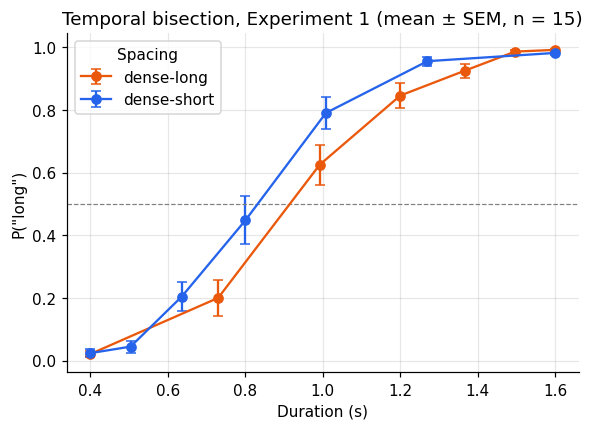

In [6]:
colors = {"dense-short": "#2563eb", "dense-long": "#ea580c"}

fig, ax = plt.subplots(figsize=(6, 4))
for spacing, g in group.groupby("spacing"):
    ax.errorbar(g["duration"], g["mean"], yerr=g["sem"], marker="o", capsize=3,
                color=colors[spacing], label=spacing)
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
ax.set(xlabel="Duration (s)", ylabel='P("long")',
       title="Temporal bisection, Experiment 1 (mean ± SEM, n = 15)")
ax.legend(title="Spacing")
plt.show()

The two sets share their extremes, yet the curves differ: the *dense-short* curve lies to the
left, so the same physical duration is called "long" more often when most durations in the set
are short. That is what one expects if the reference is not the midpoint of the two extremes but
the mean of the whole stimulus set, which is lower for the dense-short set. This is the
ensemble-distribution account proposed in the paper.

Group means can hide very different individuals, so it is always worth plotting every
participant too. `plt.subplots` with `sharex` and `sharey` gives a grid of small multiples.

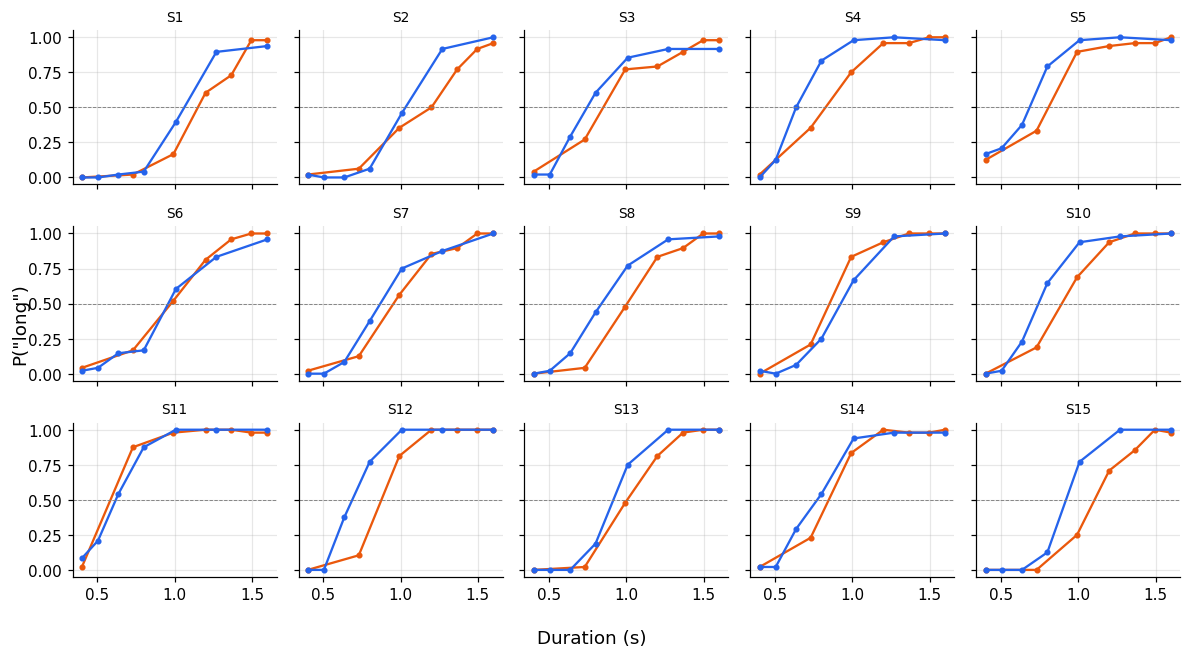

In [7]:
subjects = sorted(per_subject["subject"].unique())
fig, axes = plt.subplots(3, 5, figsize=(11, 6), sharex=True, sharey=True)
for ax, s in zip(axes.flat, subjects):
    for spacing, g in per_subject.query("subject == @s").groupby("spacing"):
        ax.plot(g["duration"], g["long"], marker=".", color=colors[spacing])
    ax.set_title(f"S{s}", fontsize=9)
    ax.axhline(0.5, color="grey", lw=0.6, ls="--")
fig.supxlabel("Duration (s)")
fig.supylabel('P("long")')
fig.tight_layout()
plt.show()

## A first summary statistic: the bisection point

The *bisection point* (BP) is the duration judged "long" on half of the trials. A model-free
estimate is the point where the curve crosses 0.5, found by linear interpolation between the two
neighbouring durations. Notebook 4 replaces this with a fitted psychometric function.

Writing it as a small function and applying it per participant and condition keeps the analysis
readable.

In [8]:
def bisection_point(duration, p_long):
    """Linear interpolation of the first crossing of 0.5."""
    duration, p_long = np.asarray(duration), np.asarray(p_long)
    above = np.flatnonzero(p_long >= 0.5)
    if len(above) == 0 or above[0] == 0:
        return np.nan
    i = above[0]
    x0, x1, y0, y1 = duration[i - 1], duration[i], p_long[i - 1], p_long[i]
    return x0 + (0.5 - y0) * (x1 - x0) / (y1 - y0)

bp = (per_subject.groupby(["subject", "spacing"])
                 .apply(lambda g: bisection_point(g["duration"], g["long"]), include_groups=False)
                 .rename("bp").reset_index())
bp_wide = bp.pivot(index="subject", columns="spacing", values="bp")
print(bp_wide.round(3).head())
print()
print(bp_wide.agg(["mean", "std"]).round(3))

spacing  dense-long  dense-short
subject                         
1             1.150        1.063
2             1.200        1.032
3             0.850        0.745
4             0.827        0.636
5             0.808        0.685

spacing  dense-long  dense-short
mean          0.929        0.827
std           0.155        0.141


Pivoting to a wide table (one row per participant, one column per condition) makes paired
comparisons natural. A paired plot shows every participant's shift at once.

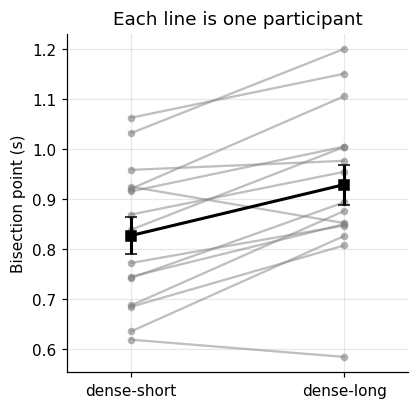

BP shift (dense-long − dense-short): 0.102 s, positive in 13 of 15 participants


In [9]:
fig, ax = plt.subplots(figsize=(4, 4))
order = ["dense-short", "dense-long"]
for _, row in bp_wide[order].iterrows():
    ax.plot([0, 1], row.values, color="grey", alpha=0.5, marker="o", ms=4)
ax.errorbar([0, 1], bp_wide[order].mean(), yerr=bp_wide[order].sem(),
            color="black", lw=2, marker="s", capsize=4)
ax.set(xticks=[0, 1], xticklabels=order, xlim=(-0.3, 1.3),
       ylabel="Bisection point (s)", title="Each line is one participant")
plt.show()

shift = bp_wide["dense-long"] - bp_wide["dense-short"]
print(f"BP shift (dense-long − dense-short): {shift.mean():.3f} s, "
      f"positive in {(shift > 0).sum()} of {shift.notna().sum()} participants")

Whether a shift of this size could be due to chance is a statistical question, and that is the
subject of the next notebook.

## Summary

- Check the codebook against the data: unique values, cross-tabulations, trial counts.
- Keep data tidy: one row per trial. Filter with `query`, add columns with `assign`.
- Aggregate in two stages: within participants first, then across participants.
- Plot the individuals as well as the mean.
- Wrap a computation in a function and apply it with `groupby`, then `pivot` for paired
  comparisons.